# PIGTAILS practical: from label maps to augmented 3D brains
A step-by-step student notebook based on the label-to-image workflow in [PIGSKIN](https://github.com/dadashkarimi/pigskin), especially Pig.ipynb and PigGMM-96.ipynb.

**Goal:** understand volumes, labels, masks, synthetic contrast, shared spatial transformations, and cuts through a synthetic brain. No model training is required.

**Data:** the default loads a real human anatomical segmentation from SynthSeg's public training examples. It is not the lab water data. Synthetic intensities are generated from its real anatomical labels; no original MRI intensity image is supplied.

**Learning sequence (about 2–3 hours):**
1. Inspect a volume and its physical coordinates.
2. Understand SynthStrip, SynthSeg, and label-to-image generation.
3. Randomize contrast, noise, blur, and bias.
4. Apply the same spatial warp to labels and image.
5. Extract sagittal/coronal/axial and oblique planes; remove a half-space.
6. Export aligned image/label/mask pairs and a reproducible manifest.

**Important:** pretrained human SynthSeg/SynthStrip models are not validated pig anatomy tools. For pig water scans, use reviewed pig masks/labels or a validated pig-specific pipeline. A failed prediction is not ground truth.

## 1. Environment
Use a fresh Python environment with Jupyter. Run the installation cell once, then restart the kernel if needed. The core lesson uses NumPy/SciPy and does not need TensorFlow or FreeSurfer. The optional model sections require separate installations.

All displayed views use RAS voxel axes after canonical reorientation. Voxel coordinates are indices; world coordinates are millimeters only when the input header declares millimeter units.

In [1]:
# Uncomment once in a fresh environment:
# %pip install numpy scipy nibabel matplotlib jupyter

from pathlib import Path
import json, sys, hashlib, subprocess, shutil, importlib.metadata
import numpy as np
import nibabel as nib
from nibabel.processing import resample_from_to
from scipy import ndimage as ndi
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt

SEED = 2026
OUT = Path("pigtails_student_outputs")
OUT.mkdir(exist_ok=True)
print("Python:", sys.version)
for package in ["numpy", "scipy", "nibabel", "matplotlib"]:
    print(package, importlib.metadata.version(package))

Python: 3.11.18 (main, Oct 26 2026, 02:48:34) [GCC 13.3.0]
numpy 2.4.6
scipy 1.17.1
nibabel 5.5.0
matplotlib 3.11.2


## 2. Download and load real segmented anatomy
The default uses training_seg_01.nii.gz from the official SynthSeg repository, at a pinned revision. We check its Git blob SHA, load the NIfTI with nibabel, inspect its original orientation, reorient to RAS, and resample categorical labels to 2 mm using nearest-neighbor interpolation.

**This is a real anatomical segmentation, not a measured intensity scan.** IDs 2/41 denote left/right cerebral white matter and 3/42 denote cortex. Nonzero labels also include surrounding tissues, so a brain target uses an explicit list of standard brain structures, including ventricular spaces but excluding extracerebral CSF 24.

For lab water data, set USE_LAB_DATA and supply the image, reviewed labels, and binary brain mask. Grid resampling does not register anatomy.

In [2]:
USE_LAB_DATA = False
WATER_PATH = Path("/replace/with/water.nii.gz")
LABEL_PATH = Path("/replace/with/reviewed_labels.nii.gz")
BRAIN_MASK_PATH = Path("/replace/with/reviewed_brain_mask.nii.gz")

def load_3d(path):
    image = nib.as_closest_canonical(nib.load(str(path)))
    if len(image.shape) != 3:
        raise ValueError(f"{path}: expected 3D, got {image.shape}. Select the intended volume explicitly.")
    if image.header.get_xyzt_units()[0] != "mm":
        raise ValueError("Confirm physical units and set a correct header before continuing.")
    return image

def integer_labels(image):
    a = image.get_fdata()
    if not np.isfinite(a).all() or not np.allclose(a, np.round(a)):
        raise ValueError("Labels must contain finite integers.")
    if a.min() < 0:
        raise ValueError("Use nonnegative label IDs.")
    return a.astype(np.int32)

if USE_LAB_DATA:
    source = load_3d(WATER_PATH)
    lab_source = load_3d(LABEL_PATH)
    mask_source = load_3d(BRAIN_MASK_PATH)
    integer_labels(lab_source)
    if not set(np.unique(integer_labels(mask_source))).issubset({0, 1}):
        raise ValueError("Brain mask must be binary.")
    labels = integer_labels(resample_from_to(lab_source, source, order=0))
    brain_mask = resample_from_to(mask_source, source, order=0).get_fdata() > 0
    water = source.get_fdata(dtype=np.float32)
    if not np.isfinite(water).all():
        raise ValueError("Water image has nonfinite values.")
    affine = source.affine.copy()
else:
    import urllib.request
    revision = "2a2aa3bbfccb83f8253a51ca8b329b9938a2646d"
    url = f"https://raw.githubusercontent.com/BBillot/SynthSeg/{revision}/data/training_label_maps/training_seg_01.nii.gz"
    example_path = OUT/"training_seg_01.nii.gz"
    if not example_path.exists():
        urllib.request.urlretrieve(url, example_path)
    raw = example_path.read_bytes()
    blob_sha = hashlib.sha1(b"blob " + str(len(raw)).encode() + b"\0" + raw).hexdigest()
    assert blob_sha == "ea35306c23022b2efc44ee5072547760744f8f38"
    native = nib.load(str(example_path))
    print("Loaded segmentation:", example_path)
    print("Original:", native.shape, nib.aff2axcodes(native.affine))
    from nibabel.processing import resample_to_output
    canonical = nib.as_closest_canonical(native)
    source = resample_to_output(canonical, voxel_sizes=(2, 2, 2), order=0)
    labels = integer_labels(source)
    affine = source.affine.copy()
    brain_ids = [2,3,4,5,7,8,10,11,12,13,14,15,16,17,18,26,28,
                 41,42,43,44,46,47,49,50,51,52,53,54,58,60]
    brain_mask = np.isin(labels, brain_ids)
    water = None  # no measured intensity image in the public segmentation example
assert brain_mask.any() and (~brain_mask).any()
assert 0 in labels, "Keep an explicit background label."
print("Shape:", labels.shape, "spacing:", nib.affines.voxel_sizes(affine))
print("Axes:", nib.aff2axcodes(affine), "label IDs:", np.unique(labels))

Loaded segmentation: pigtails_student_outputs/training_seg_01.nii.gz
Original: (256, 256, 256) ('L', 'I', 'A')


Shape: (129, 129, 129) spacing: [2. 2. 2.]
Axes: ('R', 'A', 'S') label IDs: [  0   2   3   4   5   7   8  10  11  12  13  14  15  16  17  18  24  25
  26  28  30  41  42  43  44  46  47  49  50  51  52  53  54  57  58  60
  62  72  85 136 137 163 164 502 506 507 508 509 511 512 514 515 516 530]


## 3. Inspect three views
After RAS reorientation, axis 0 increases toward Right, axis 1 toward Anterior, and axis 2 toward Superior. The figures use a teaching convention, not radiological left/right display. On an oblique input grid these index slices are approximately anatomical; world-space slicing later gives exact physical planes.

**Checkpoint:** identify background, brain, and surrounding tissue. For lab data, inspect overlays across the entire volume before synthesis.

Loaded real anatomical segmentation; measured intensities are not supplied.


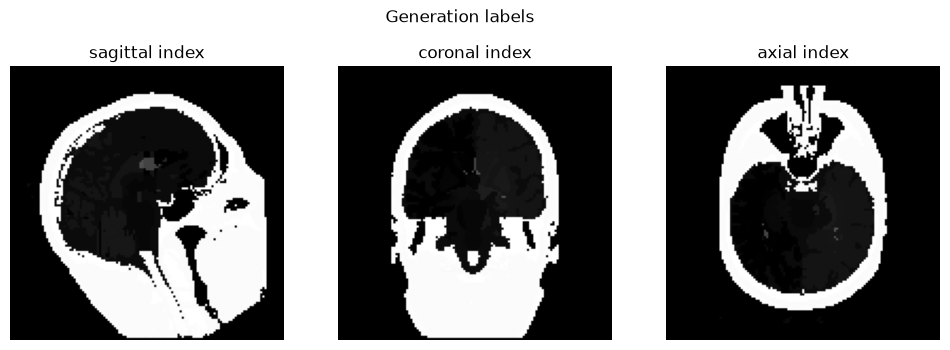

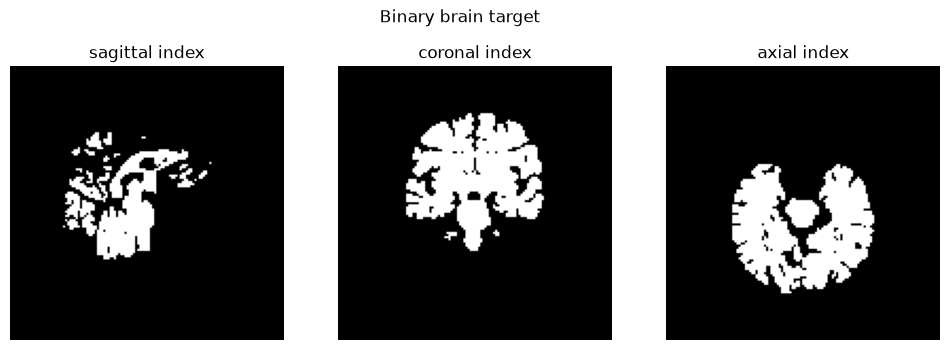

2 left cerebral white matter voxels: 27347
3 left cerebral cortex voxels: 25361
4 left lateral ventricle voxels: 2158
16 brainstem voxels: 2491
17 left hippocampus voxels: 306
24 extracerebral CSF voxels: 52061
41 right cerebral white matter voxels: 27436
42 right cerebral cortex voxels: 24918


In [3]:
def views(volume, title, mask=None):
    centre = np.array(volume.shape)//2
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for axis, (ax, name) in enumerate(zip(axes, ["sagittal index", "coronal index", "axial index"])):
        sl = np.take(volume, centre[axis], axis=axis).T
        ax.imshow(sl, origin="lower", cmap="gray")
        if mask is not None:
            ms = np.take(mask, centre[axis], axis=axis).T
            if ms.any() and not ms.all():
                ax.contour(ms, levels=[.5], colors="lime", linewidths=.7)
        ax.set_title(name); ax.set_axis_off()
    fig.suptitle(title); plt.show()

if USE_LAB_DATA:
    views(water, "Lab water image", brain_mask)
else:
    print("Loaded real anatomical segmentation; measured intensities are not supplied.")
views(labels, "Generation labels")
views(brain_mask, "Binary brain target")
names = {2:"left cerebral white matter",3:"left cerebral cortex",4:"left lateral ventricle",
         16:"brainstem",17:"left hippocampus",24:"extracerebral CSF",
         41:"right cerebral white matter",42:"right cerebral cortex"}
for k, name in names.items():
    print(k, name, "voxels:", int((labels == k).sum()))


## 4. What the tools actually do
| Component | Input | Output | Purpose |
|---|---|---|---|
| SynthStrip inference | scan | stripped scan + brain mask | remove non-brain tissue |
| SynthSeg inference | scan | anatomical segmentation | predict human anatomical regions |
| SynthSeg BrainGenerator | label map | randomized synthetic image + corresponding labels | label-to-image training data |
| PIGSKIN generation | pig labels plus surrounding shapes | synthetic image and task target | pig skull-stripping training |

SynthStrip and SynthSeg inference do not generate synthetic scans. Their training uses synthesis ideas. Below we first implement a small **educational approximation**, then show the actual SynthSeg generator.

Official references: [SynthStrip](https://surfer.nmr.mgh.harvard.edu/docs/synthstrip/), [SynthSeg](https://www.freesurfer.net/fswiki/SynthSeg), [BrainGenerator source](https://github.com/BBillot/SynthSeg/blob/master/SynthSeg/brain_generator.py).

### Optional inference on appropriate data
Use a configured FreeSurfer installation, with its model files and environment ready. These commands are disabled by default. Read local --help output for your installed release. On pig data, inspect results as experimental outputs; do not replace reviewed labels automatically.

In [4]:
RUN_INFERENCE = False
if RUN_INFERENCE:
    if not USE_LAB_DATA:
        raise ValueError("Choose an appropriate real scan first.")
    for executable in ["mri_synthstrip", "mri_synthseg"]:
        if shutil.which(executable) is None:
            raise RuntimeError(f"Configure FreeSurfer first: missing {executable}")
    commands = [
        ["mri_synthstrip", "-i", str(WATER_PATH), "-o", str(OUT/"stripped.nii.gz"),
         "-m", str(OUT/"predicted_mask.nii.gz")],
        ["mri_synthseg", "--i", str(WATER_PATH), "--o", str(OUT/"predicted_seg.nii.gz"), "--cpu"]
    ]
    for command in commands:
        print(command)
        subprocess.run(command, check=True)

## 5. Build contrast from labels
For each region k, draw a mean and standard deviation, then draw voxel intensities from a Gaussian. Different random seeds produce different contrast from the same anatomy.

This does not reproduce quantitative water physics or calibrate MRI signal. For that, measure appropriate acquisition-specific distributions separately. Never blur label IDs: labels are categories.

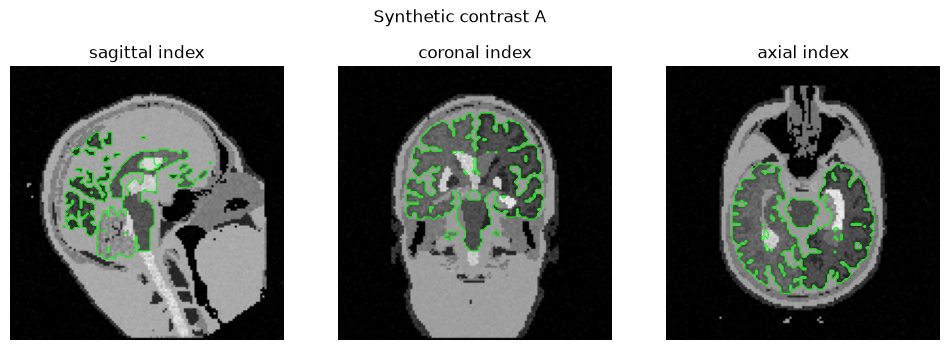

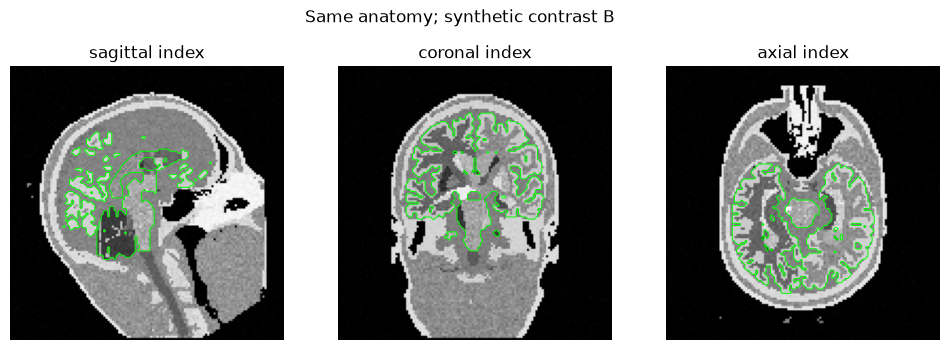

{'0': {'mean': 0.0, 'std': 0.018946740683771807}, '2': {'mean': 0.42921505425995854, 'std': 0.03577519158513822}, '3': {'mean': 0.35846873495508064, 'std': 0.031552157612079905}, '4': {'mean': 0.8676642604322429, 'std': 0.059299575120186764}, '5': {'mean': 0.6215861088223912, 'std': 0.036491113559395626}, '7': {'mean': 0.5566020969424952, 'std': 0.01056800542770823}, '8': {'mean': 0.4712853058043689, 'std': 0.04159586525310234}, '10': {'mean': 0.4705952002953805, 'std': 0.029254170873093337}, '11': {'mean': 0.36626560043570916, 'std': 0.03615441952548716}, '12': {'mean': 0.8662720757616579, 'std': 0.01987137754139295}, '13': {'mean': 0.22110682731187623, 'std': 0.05658130768987465}, '14': {'mean': 0.8069901958903373, 'std': 0.04043375669585618}, '15': {'mean': 0.8324124845688871, 'std': 0.015561074663037789}, '16': {'mean': 0.32406562345005907, 'std': 0.028797908743946776}, '17': {'mean': 0.3878848684804366, 'std': 0.03848557633821952}, '18': {'mean': 0.4766900638986543, 'std': 0.02636

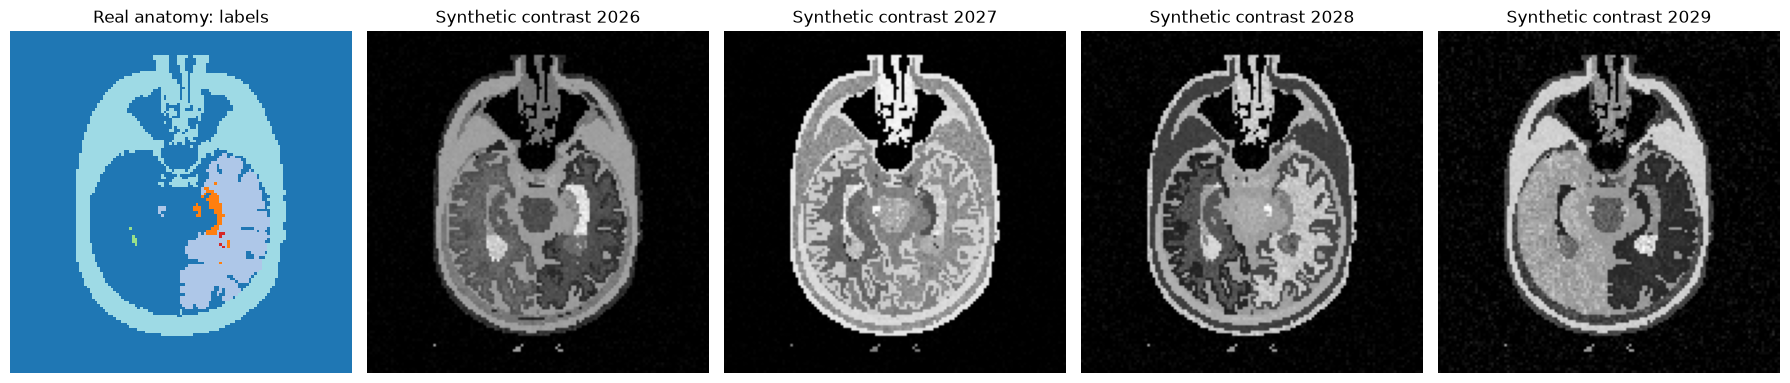

In [5]:
def synthesize(label_map, seed):
    rng = np.random.default_rng(seed)
    image = np.zeros(label_map.shape, np.float32)
    parameters = {}
    for k in np.unique(label_map):
        mean = 0.0 if k == 0 else float(rng.uniform(.15, .95))
        std = float(rng.uniform(.01, .06))
        region = label_map == k
        image[region] = rng.normal(mean, std, region.sum())
        parameters[str(k)] = {"mean": mean, "std": std}
    return np.clip(image, 0, None), parameters

clean, contrast_params = synthesize(labels, SEED)
other, _ = synthesize(labels, SEED+1)
views(clean, "Synthetic contrast A", brain_mask)
views(other, "Same anatomy; synthetic contrast B", brain_mask)
print(contrast_params)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
z = labels.shape[2]//2
axes[0].imshow(labels[:,:,z].T, origin="lower", cmap="tab20", interpolation="nearest")
axes[0].set_title("Real anatomy: labels")
for ax, seed in zip(axes[1:], [2026, 2027, 2028, 2029]):
    synthetic, _ = synthesize(labels, seed)
    ax.imshow(synthetic[:,:,z].T, origin="lower", cmap="gray")
    ax.set_title(f"Synthetic contrast {seed}")
for ax in axes: ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT/"real_brain_synthetic_examples.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Appearance augmentation: bias, blur, noise
A smooth multiplicative field mimics intensity inhomogeneity. Blur reduces sharp detail and noise perturbs observations. These change the image, so the segmentation target stays fixed.

**Exercise:** change one parameter at a time. Explain why a bright region need not be the same tissue across synthetic examples.

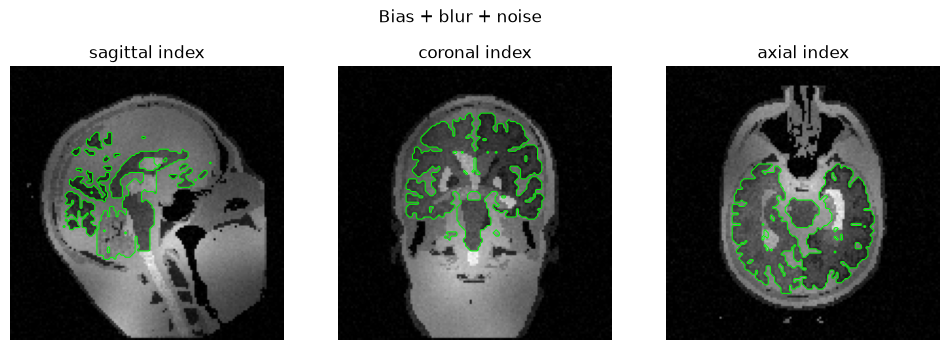

In [6]:
def appearance(image, seed, bias_strength=.25, blur_mm=.7, noise_std=.025):
    rng = np.random.default_rng(seed)
    field = ndi.gaussian_filter(rng.normal(size=image.shape).astype(np.float32), sigma=12)
    field /= max(float(field.std()), 1e-6)
    biased = image * np.exp(bias_strength*field)
    sigma = blur_mm / nib.affines.voxel_sizes(affine)
    blurred = ndi.gaussian_filter(biased, sigma=sigma)
    noisy = blurred + rng.normal(0, noise_std, image.shape)
    return np.clip(noisy, 0, None).astype(np.float32)

aug_image = appearance(clean, SEED+2)
views(aug_image, "Bias + blur + noise", brain_mask)

## 7. Shared 3D spatial augmentation
Resampling asks: **for this output voxel, where do I sample the input?** We construct a pull transform in world coordinates, then convert to voxel coordinates. Intensities use linear interpolation; labels/masks use nearest neighbor. All three use identical coordinates.

The output stays on the input grid, so its NIfTI affine stays unchanged. Anatomy moves within that grid. Padding may clip anatomy: compare foreground voxel counts and inspect every example.

The smooth displacement field is an introductory elastic warp in voxels. It is not constrained to be diffeomorphic or anatomically plausible.

Brain voxel count before/after: 136040 145735


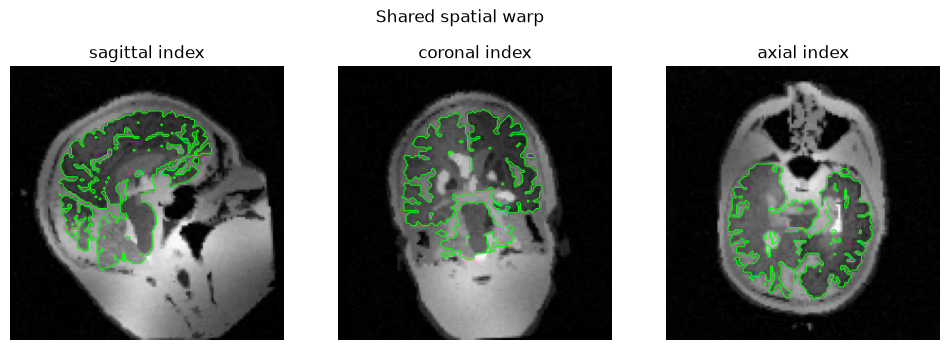

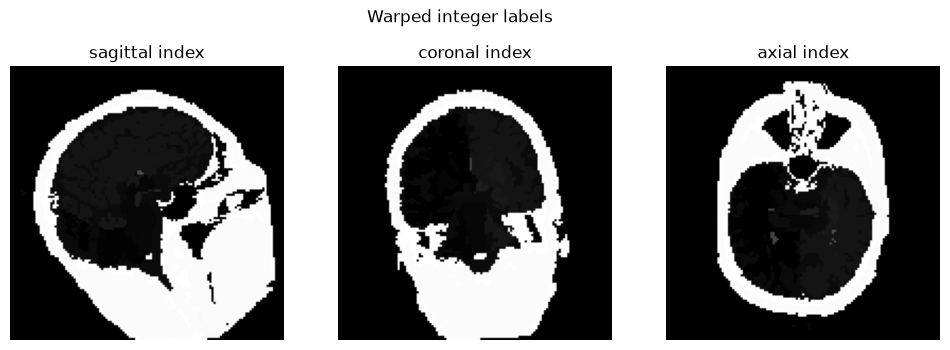

In [7]:
def sampling_coordinates(shape, affine, seed, elastic_vox=.6):
    rng = np.random.default_rng(seed)
    angles = rng.uniform(-8, 8, 3)
    rotation = Rotation.from_euler("xyz", angles, degrees=True).as_matrix()
    scale = float(rng.uniform(.95, 1.05))
    centre_world = nib.affines.apply_affine(affine, (np.array(shape)-1)/2)
    forward = np.eye(4)
    forward[:3, :3] = rotation * scale
    translation_mm = rng.uniform(-2, 2, 3)
    forward[:3, 3] = centre_world + translation_mm - forward[:3, :3] @ centre_world
    pull = np.linalg.inv(affine) @ np.linalg.inv(forward) @ affine
    ijk = np.indices(shape, dtype=np.float32).reshape(3, -1)
    coords = (pull[:3, :3] @ ijk + pull[:3, 3, None]).reshape((3,)+shape)
    for axis in range(3):
        d = ndi.gaussian_filter(rng.normal(size=shape).astype(np.float32), 10)
        d *= elastic_vox / max(float(d.std()), 1e-6)
        coords[axis] += d
    return coords, {"forward_world": forward.tolist(), "angles_deg": angles.tolist(),
                    "scale": scale, "translation_mm": translation_mm.tolist(),
                    "elastic_vox": elastic_vox, "seed": seed}

coords, spatial_params = sampling_coordinates(labels.shape, affine, SEED+3)
warped_image = ndi.map_coordinates(aug_image, coords, order=1, mode="constant", cval=0)
warped_labels = ndi.map_coordinates(labels, coords, order=0, mode="constant", cval=0)
warped_mask = ndi.map_coordinates(brain_mask.astype(np.uint8), coords, order=0,
                                 mode="constant", cval=0).astype(bool)
assert set(np.unique(warped_labels)).issubset(set(np.unique(labels)))
assert warped_mask.any()
print("Brain voxel count before/after:", brain_mask.sum(), warped_mask.sum())
views(warped_image, "Shared spatial warp", warped_mask)
views(warped_labels, "Warped integer labels")

## 8. Actual SynthSeg label-to-image generation (optional)
Use a **separate environment** matching the official [SynthSeg installation instructions](https://github.com/BBillot/SynthSeg). Its TensorFlow/Keras dependencies may differ from a modern notebook environment. Clone the official repository, record its commit, and expose its root on Python's path. Do not install an unrelated package with a similar name.

The inspected BrainGenerator implementation exposes **generate_brain()**. Here flipping is disabled because arbitrary pig IDs do not encode the paired left/right ordering required for label swapping. This section does not load pretrained inference weights.

The returned arrays are a new synthetic grid. For this introductory example we save with an explicit synthetic 1 mm RAS grid, rather than claiming native registration. To use the actual generator result for plane cutting, set USE_SYNTHSEG_FOR_CUTS after inspecting it.

In [8]:
RUN_SYNTHSEG_GENERATOR = False
USE_SYNTHSEG_FOR_CUTS = False
SYNTHSEG_ROOT = Path("/replace/with/SynthSeg")

if RUN_SYNTHSEG_GENERATOR:
    sys.path.insert(0, str(SYNTHSEG_ROOT.resolve()))
    import tensorflow as tf
    from SynthSeg.brain_generator import BrainGenerator
    np.random.seed(SEED)
    tf.random.set_seed(SEED)
    input_file = OUT/"generation_labels.nii.gz"
    nifti = nib.Nifti1Image(labels.astype(np.int32), affine)
    nifti.header.set_xyzt_units("mm")
    nib.save(nifti, input_file)
    generator = BrainGenerator(
        labels_dir=str(input_file), generation_labels=np.unique(labels),
        output_labels=np.unique(labels), batchsize=1, n_channels=1,
        output_shape=[96, 96, 96], target_res=1.0,
        flipping=False, scaling_bounds=.1, rotation_bounds=10,
        nonlin_std=2., randomise_res=True, bias_field_std=.3)
    sg_image, sg_labels = generator.generate_brain()
    sg_image = np.asarray(sg_image, dtype=np.float32)
    sg_labels = np.asarray(sg_labels, dtype=np.int32)
    assert sg_image.ndim == sg_labels.ndim == 3
    assert sg_image.shape == sg_labels.shape
    assert set(np.unique(sg_labels)).issubset(set(np.unique(labels)))
    views(sg_image, "Actual SynthSeg generator result")
    print("Record this revision:", subprocess.check_output(
        ["git", "-C", str(SYNTHSEG_ROOT), "rev-parse", "HEAD"], text=True).strip())

cut_image, cut_labels, cut_mask, cut_affine = warped_image, warped_labels, warped_mask, affine
if USE_SYNTHSEG_FOR_CUTS:
    if not RUN_SYNTHSEG_GENERATOR:
        raise ValueError("Run the actual generator first.")
    # Derive which label IDs denote brain only after inspecting the reviewed mask.
    brain_ids = np.unique(labels[brain_mask])
    if 0 in brain_ids or np.isin(labels[~brain_mask], brain_ids).any():
        raise ValueError("Brain and non-brain share label IDs. Supply an explicit task label mapping.")
    cut_image, cut_labels = sg_image, sg_labels
    cut_mask = np.isin(sg_labels, brain_ids)
    cut_affine = np.eye(4)  # declared synthetic 1 mm RAS grid, not native coordinates
    cut_affine[:3, 3] = -(np.array(sg_image.shape)-1)/2

## 9. Cut exact planes in physical space
A plane is described by a centre p and unit normal n. Choose two perpendicular unit vectors u and v spanning it. Plane pixels correspond to p + a*u + b*v in world coordinates. Convert these positions through the inverse affine and sample the volume.

The same coordinates extract image and label slices; labels use nearest neighbor. This is a zero-thickness reslice, not an MRI slice acquisition model. A thick slab requires averaging image samples across the normal; do not average categorical IDs.

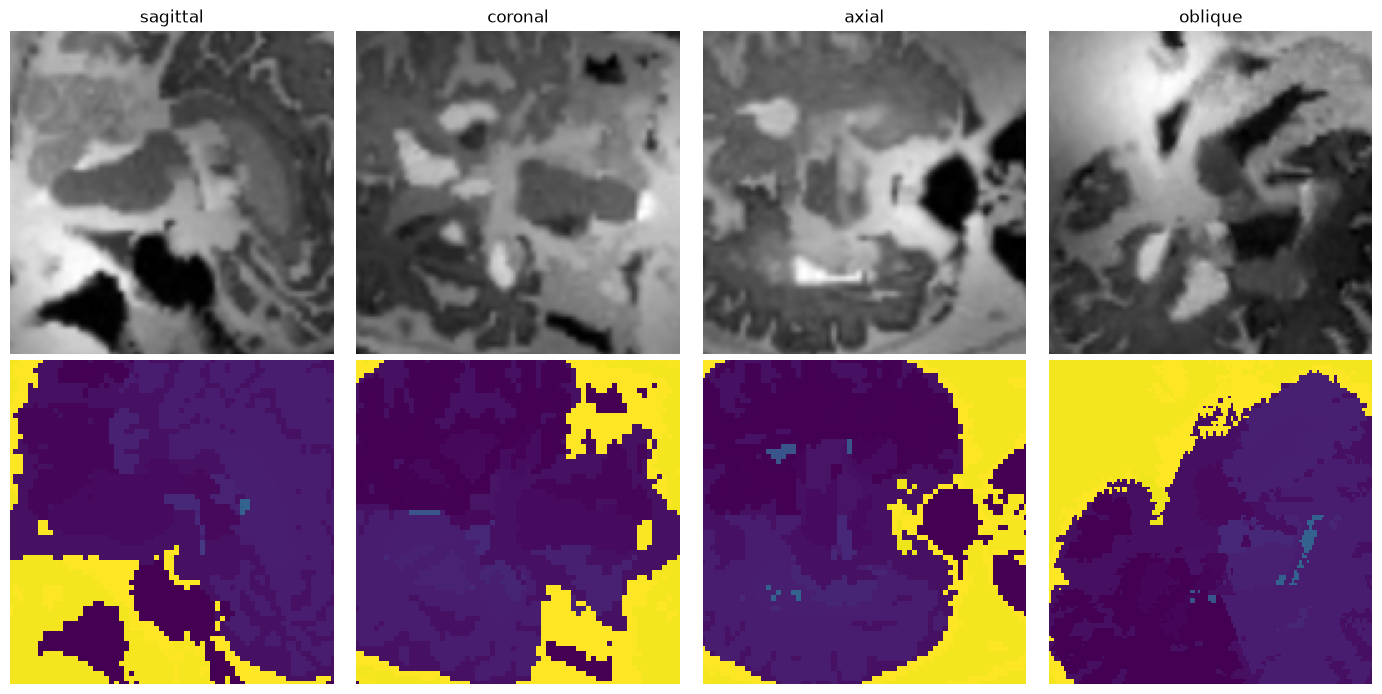

In [9]:
def plane_coordinates(affine, centre_mm, normal, size=128, spacing_mm=1.0):
    normal = np.asarray(normal, float)
    if normal.shape != (3,) or not np.isfinite(normal).all() or np.linalg.norm(normal) == 0:
        raise ValueError("Normal must be a finite nonzero 3-vector.")
    n = normal / np.linalg.norm(normal)
    helper = np.eye(3)[np.argmin(np.abs(n))]
    u = np.cross(n, helper); u /= np.linalg.norm(u)
    v = np.cross(n, u)
    ticks = (np.arange(size)-(size-1)/2)*spacing_mm
    a, b = np.meshgrid(ticks, ticks, indexing="ij")
    world = np.asarray(centre_mm)[:, None, None] + u[:, None, None]*a + v[:, None, None]*b
    inverse = np.linalg.inv(affine)
    voxels = (inverse[:3, :3] @ world.reshape(3, -1) + inverse[:3, 3, None]).reshape(3, size, size)
    return voxels, {"centre_mm": np.asarray(centre_mm).tolist(), "normal": n.tolist(),
                    "u": u.tolist(), "v": v.tolist(), "spacing_mm": spacing_mm,
                    "size": size, "coordinate_system": "RAS"}

centre = nib.affines.apply_affine(cut_affine, (np.array(cut_image.shape)-1)/2)
planes = {"sagittal": [1, 0, 0], "coronal": [0, 1, 0],
          "axial": [0, 0, 1], "oblique": [1, 1, .6]}
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
plane_exports = {}
for column, (name, normal) in enumerate(planes.items()):
    pc, metadata = plane_coordinates(cut_affine, centre, normal)
    image_slice = ndi.map_coordinates(cut_image, pc, order=1, mode="constant", cval=0)
    label_slice = ndi.map_coordinates(cut_labels, pc, order=0, mode="constant", cval=0)
    axes[0, column].imshow(image_slice.T, origin="lower", cmap="gray")
    axes[1, column].imshow(label_slice.T, origin="lower", interpolation="nearest")
    axes[0, column].set_title(name)
    for row in range(2): axes[row, column].set_axis_off()
    plane_exports[name] = (image_slice, label_slice, metadata)
fig.tight_layout()
fig.savefig(OUT/"real_brain_plane_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Remove one side of a plane
Reslicing shows a plane. A **half-space cut** removes all voxels on one side of it. These are different operations.

For a point x, signed distance d = n dot (x - p). Keep d >= 0. Apply the same mask to image, labels, and brain target; save the removed-brain mask separately. Zeroing removed anatomy simulates an idealized absence, not tissue deformation, a wound, or realistic surgical physics.

Retained brain fraction: 0.38833499159433216


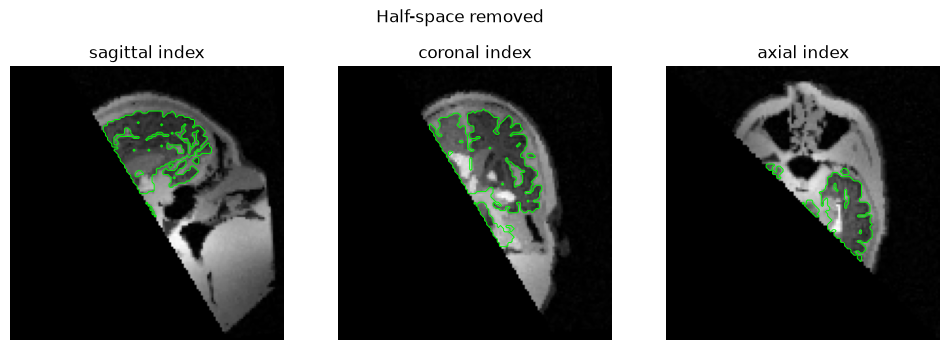

In [10]:
normal = np.array([1., 1., .6]); normal /= np.linalg.norm(normal)
indices = np.indices(cut_image.shape, dtype=np.float32).reshape(3, -1)
world = cut_affine[:3, :3] @ indices + cut_affine[:3, 3, None]
distance = (normal @ (world - centre[:, None])).reshape(cut_image.shape)
keep = distance >= 0
cut_volume = np.where(keep, cut_image, 0).astype(np.float32)
cut_target = cut_mask & keep
removed_brain = cut_mask & ~keep
cut_regions = np.where(keep, cut_labels, 0).astype(np.int32)
assert np.array_equal(cut_target | removed_brain, cut_mask)
assert not np.any(cut_target & removed_brain)
print("Retained brain fraction:", cut_target.sum()/cut_mask.sum())
views(cut_volume, "Half-space removed", cut_target)

## 11. Export a reproducible training example
Each image and target has the same shape and affine. The manifest describes the random seed, contrast, spatial warp, plane, software, and source hashes. Output labels remain integer IDs.

For a dataset, split **original subjects before augmentation**. Every derivative of a subject belongs to the same train/validation/test split. Different seeds from one brain are not independent subjects.

In [11]:
def save_volume(name, data, dtype, matrix):
    image = nib.Nifti1Image(np.asarray(data, dtype=dtype), matrix)
    image.header.set_xyzt_units("mm")
    nib.save(image, OUT/name)

save_volume("synthetic_image.nii.gz", cut_image, np.float32, cut_affine)
save_volume("synthetic_labels.nii.gz", cut_labels, np.int32, cut_affine)
save_volume("synthetic_brain_mask.nii.gz", cut_mask, np.uint8, cut_affine)
save_volume("cut_image.nii.gz", cut_volume, np.float32, cut_affine)
save_volume("cut_labels.nii.gz", cut_regions, np.int32, cut_affine)
save_volume("cut_brain_mask.nii.gz", cut_target, np.uint8, cut_affine)
save_volume("removed_brain_mask.nii.gz", removed_brain, np.uint8, cut_affine)
for name, (im, lab, meta) in plane_exports.items():
    np.savez_compressed(OUT/f"plane_{name}.npz", image=im, labels=lab)
    (OUT/f"plane_{name}.json").write_text(json.dumps(meta, indent=2))

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest = {
    "seed": SEED, "source_type": "lab_water" if USE_LAB_DATA else "public_real_anatomical_segmentation",
    "generator": "SynthSeg" if USE_SYNTHSEG_FOR_CUTS else "educational_numpy",
    "contrast": None if USE_SYNTHSEG_FOR_CUTS else contrast_params,
    "spatial": None if USE_SYNTHSEG_FOR_CUTS else spatial_params,
    "appearance": None if USE_SYNTHSEG_FOR_CUTS else {
        "seed": SEED+2, "bias_strength": .25, "blur_mm": .7, "noise_std": .025},
    "cut": {"centre_mm": centre.tolist(), "normal": normal.tolist(), "keep": "distance >= 0"},
    "affine": cut_affine.tolist(),
    "versions": {p: importlib.metadata.version(p) for p in ["numpy", "scipy", "nibabel", "matplotlib"]},
    "source_sha256": {str(p): sha256_file(p) for p in
                      [WATER_PATH, LABEL_PATH, BRAIN_MASK_PATH]} if USE_LAB_DATA else {str(example_path): sha256_file(example_path)},
    "note": "Educational synthesis; not quantitative water simulation."
}
(OUT/"manifest.json").write_text(json.dumps(manifest, indent=2))
saved = nib.load(str(OUT/"cut_brain_mask.nii.gz"))
assert saved.shape == cut_volume.shape
assert np.allclose(saved.affine, cut_affine)
assert set(np.unique(saved.get_fdata())).issubset({0, 1})
print("Saved:", OUT.resolve())

Saved: /home/runner/work/pigskin/pigskin/pigtails_student_outputs


## 12. Student exercises and discussion
1. Generate three contrasts with identical labels. Which properties remain fixed?
2. Disable elastic displacement. Compare rigid/scale transforms with elastic warps.
3. Cut at centre + [0, 0, 10] mm. How does retained brain volume change?
4. Try plane normals [1, 0, 0], [0, 1, 0], and [0, 0, 1]. Explain each in RAS.
5. Sample five parallel oblique planes 2 mm apart. Save their centres and labels.
6. Create three cuts of increasing severity; report removed-brain fraction.
7. Compare the educational generator with actual SynthSeg output. Which artifacts differ?
8. Replace the public human example with reviewed lab water data. Show full-volume mask/label QC before synthesis.

**Deliver to your supervisor:** a screenshot of image/target overlays, an oblique slice, one cut volume, the manifest, and a short explanation of interpolation and subject-level splitting.

**Before a PIGTAILS experiment:** agree on what a cut represents (reslice, slab, missing half-space, or tissue resection); define valid plane ranges; determine whether surrounding tissues should also be removed; validate pig anatomy and acquisition realism.

### Provenance and validation status
Prepared from the public PIGSKIN repository inspected on 2026-11-09 and the official SynthSeg BrainGenerator source. The actual lab water files were unavailable. Notebook execution and external model inference have **not** been verified in this authoring environment. Run top-to-bottom in a fresh kernel before assigning it; optional model sections remain off by default.

The default now uses real segmented anatomy. The shown synthetic images are made with the educational NumPy Gaussian label-to-image generator. Optional FreeSurfer inference and TensorFlow SynthSeg BrainGenerator are not executed by the default lesson. See the executed notebook artifact for actual run outputs and errors.